# [Página da atividade no CERN Open Data:](https://opendata.cern.ch/record/49)

## Dia 1:

In [67]:
import numpy as np
import math

def ajuste_polinomial(x, y, sigma, M):

    # Convertendo os dados para arrays
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    sigma = np.asarray(sigma, dtype=float)

    # Número de dados experimentais
    N = len(x)

    # Matriz de ajuste
    A = np.vander(x, N=M, increasing=True)

    # Matriz ponderada
    Aw = A / sigma[:, np.newaxis]
    yw = y / sigma

    # Parâmetros do ajuste
    a_fit = np.linalg.lstsq(Aw, yw, rcond=None)[0]

    # Matriz de covariância
    cov = np.linalg.inv(Aw.T @ Aw)

    # Incertezas dos parâmetros
    sig_a = np.sqrt(np.diag(cov))

    # Valores ajustados
    yy = A @ a_fit

    # Qui-quadrado
    chisqr = np.sum(((y - yy) / sigma)**2)

    return a_fit, sig_a, yy, chisqr, cov

In [68]:
import pickle
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import norm
import pandas as pd

In [69]:
# Leia o arquivo
with open("/content/DoubleMuon_2016H_200k.pkl", "rb") as arquivo:
    dados = pickle.load(arquivo)

colunas = ["E1", "E2", "px1", "px2", "py1", "py2", "pz1", "pz2"]
# Organize os dados em uma tabela
tabela = pd.DataFrame(dados,columns = colunas)

# Numera os eventos a partir de 1
tabela.index = range(1, len(tabela) + 1)
tabela.index.name = "Evento"

# Mostre as primeiras 5 linhas
display(tabela.head())

,E1,E2,px1,px2,py1,py2,pz1,pz2
Evento,,,,,,,,
1,18.937338,32.341581,16.544305,19.141015,-5.273955,-6.863615,-7.555328,-25.149136
2,206.428566,28.917240,53.688940,11.692259,188.422076,26.447778,-65.018157,-0.041780
3,21.575747,28.090747,-15.686805,-15.519991,-12.056012,-11.712283,8.606883,20.273904
4,186.595130,96.353851,75.018869,52.220840,-27.959343,-21.444175,-168.547251,-78.084471
5,1849.145257,181.492614,5.665278,-44.469453,-326.881971,-3.983799,-1820.014905,-175.915192


In [70]:
Ntoprocess = int(input("Quantos eventos devo processar?")) #Sugestão: 20000
Min = float(input("Digite seu valor mínimo de massa(em GeV/c²): ")) #sugestão: 60
Max = float(input("Digite seu valor máximo da massa(em GeV/c²): ")) #Sugestão: 120
n = int(input("Quantos intervalos (bins) você deseja no histograma? ")) #sugetsão: 60

# Use estes valores para calcular a largura de intervalo
BinWidth = (Max - Min)/n

Quantos eventos devo processar?20000
Digite seu valor mínimo de massa(em GeV/c²): 60
Digite seu valor máximo da massa(em GeV/c²): 120
Quantos intervalos (bins) você deseja no histograma? 60


In [71]:
m_mu = 0.105658 # Massa do múon em GeV/c²
Massas = []
EnergiaCinetica = []
#Calculo das massas e da energia cinética relativística

for i in range(Ntoprocess):
  E1 = dados[i][0]
  E2 = dados[i][1]
  p1 = dados[i][2::2]
  p2 = dados[i][3::2]

#Produto escalar de Minkowski(+,-,-,-)
  p_m = E1*E2 - np.dot(p1, p2)

#massa da partícula X ao quadrado
  m_xsqr = 2*m_mu**2 + 2*p_m

# Verifica o valor antes de calcular a raiz
  if m_xsqr < 0:
    raise ValueError(f"Massa² negativa no evento {i + 1}")

#massa da partícula X
  m_x = m_xsqr**0.5

#Energia cinética relativística
  K_x = E1 + E2 - m_x

  if Min <= m_x <= Max:
    Massas.append(m_x)
    EnergiaCinetica.append(K_x)

print("Eventos processados:", Ntoprocess)
print("Eventos selecionados:", len(Massas))
print("Primeiras 5 massas (GeV/c²):", np.round(Massas[:5], 3))
print("Primeiras 5 energias cinéticas (GeV):",np.round(EnergiaCinetica[:5], 3))

Eventos processados: 20000
Eventos selecionados: 5528
Primeiras 5 massas (GeV/c²): [92.676 91.602 96.621 88.722 96.073]
Primeiras 5 energias cinéticas (GeV): [3.31659e+02 5.90000e-02 1.60104e+02 3.47510e+01 5.80220e+01]


# Dia 2:

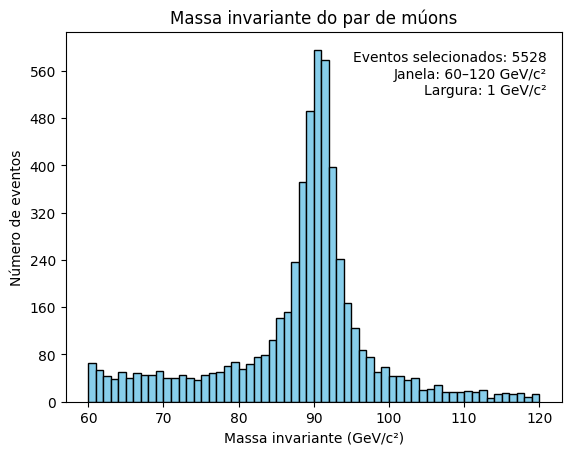

In [72]:
#Histograma das massas:
bordas = Min + np.arange(n + 1) * BinWidth
import matplotlib.pyplot as plt

plt.hist(Massas, bins = bordas, range=(Min, Max),
         color="skyblue", edgecolor="black")

plt.xlabel("Massa invariante (GeV/c²)")
plt.ylabel("Número de eventos")
plt.title("Massa invariante do par de múons")

plt.text(
    0.97, 0.95,
    f"Eventos selecionados: {len(Massas)}\n"
    f"Janela: {Min:g}–{Max:g} GeV/c²\n"
    f"Largura: {BinWidth:g} GeV/c²",
    transform=plt.gca().transAxes,
    ha="right", va="top"
)

from matplotlib.ticker import MaxNLocator
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))

plt.show()

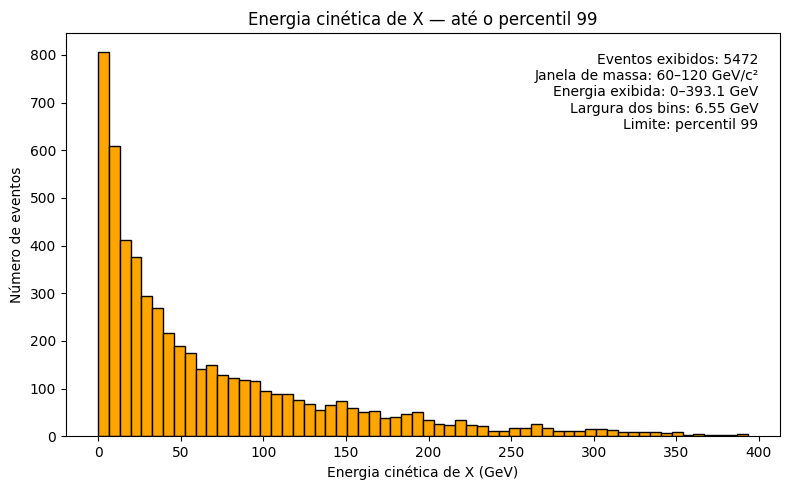

In [73]:
#Histograma da energia cinética
limite = np.percentile(EnergiaCinetica, 99)

plt.figure(figsize=(8, 5))

plt.hist(EnergiaCinetica, bins=n, range=(0, limite),
         color="orange", edgecolor="black")

plt.xlabel("Energia cinética de X (GeV)")
plt.ylabel("Número de eventos")
plt.title("Energia cinética de X — até o percentil 99")
plt.tight_layout()

quantidade_exibida = sum(0 <= K <= limite for K in EnergiaCinetica)
largura_energia = limite / n

plt.text(
    0.97, 0.95,
    f"Eventos exibidos: {quantidade_exibida}\n"
    f"Janela de massa: {Min:g}–{Max:g} GeV/c²\n"
    f"Energia exibida: 0–{limite:.1f} GeV\n"
    f"Largura dos bins: {largura_energia:.2f} GeV\n"
    f"Limite: percentil 99",
    transform=plt.gca().transAxes,
    ha="right",
    va="top"
)

plt.show()

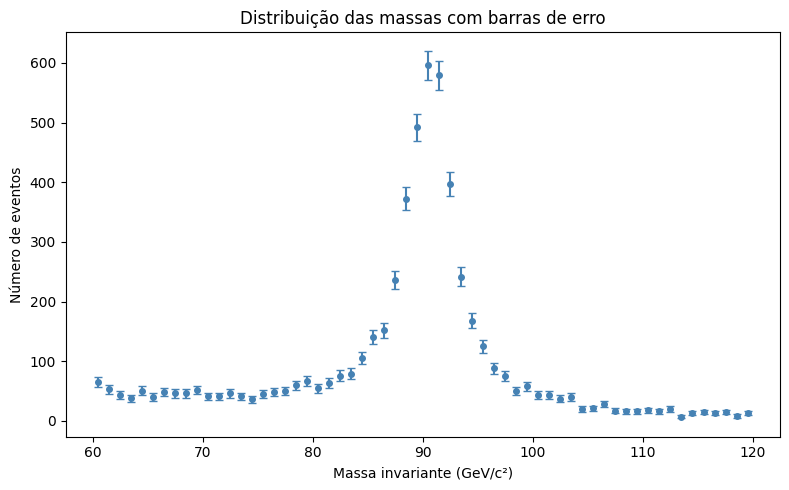

In [74]:
# Contagem em cada intervalo
contagens_m, bordas_m = np.histogram(Massas, bins=bordas)

# Centro = média entre as duas bordas do intervalo
centros_m = (bordas_m[:-1] + bordas_m[1:]) / 2

# Incertezas das contagens
erros_m = np.sqrt(contagens_m)

plt.figure(figsize=(8, 5))

plt.errorbar(
    centros_m, contagens_m,
    yerr=erros_m,
    fmt="o", markersize=4, capsize=3,
    color="steelblue"
)

plt.xlabel("Massa invariante (GeV/c²)")
plt.ylabel("Número de eventos")
plt.title("Distribuição das massas com barras de erro")
plt.tight_layout()
plt.show()

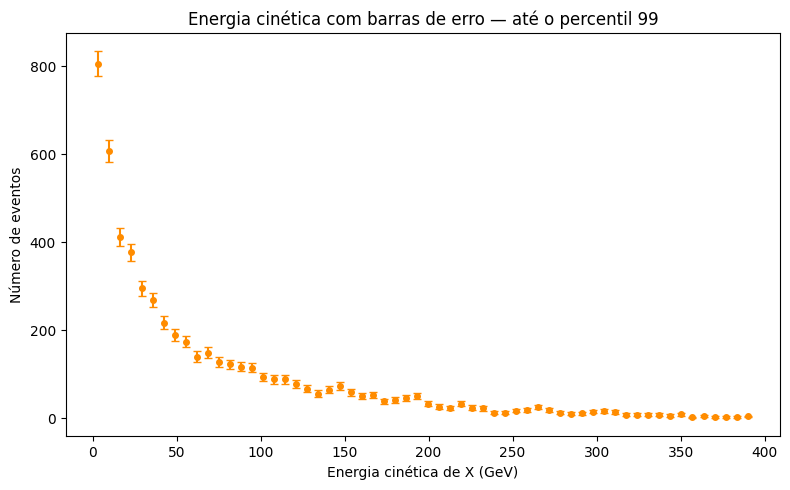

In [75]:
contagens_K, bordas_K = np.histogram(
    EnergiaCinetica, bins=n, range=(0, limite)
)

centros_K = (bordas_K[:-1] + bordas_K[1:]) / 2
erros_K = np.sqrt(contagens_K)

plt.figure(figsize=(8, 5))

plt.errorbar(
    centros_K, contagens_K,
    yerr=erros_K,
    fmt="o", markersize=4, capsize=3,
    color="darkorange"
)

plt.xlabel("Energia cinética de X (GeV)")
plt.ylabel("Número de eventos")
plt.title("Energia cinética com barras de erro — até o percentil 99")
plt.tight_layout()
plt.show()

In [76]:
# Limites da região do pico
peakmin = float(input("Massa mínima do pico (GeV/c²): ")) #sugestão: 78
peakmax = float(input("Massa máxima do pico (GeV/c²): ")) #sugestão: 104

Massa mínima do pico (GeV/c²): 78
Massa máxima do pico (GeV/c²): 104


In [77]:
fora_do_pico = (centros_m < peakmin) | (centros_m > peakmax)

x_fundo = centros_m[fora_do_pico]
y_fundo = contagens_m[fora_do_pico]
erro_fundo = erros_m[fora_do_pico]

In [78]:
numpars = int(input("Número de parâmetros do polinômio: ")) # Sugestão: 2

# Confere se as incertezas permitem usar a função
if np.any(erro_fundo <= 0):
    raise ValueError("Há intervalos com erro zero; precisamos tratá-los antes do ajuste.")

if not 1 <= numpars < len(x_fundo):
    raise ValueError("Use pelo menos 1 parâmetro e menos parâmetros que pontos.")

# Ajuste do fundo
a_fit, sig_a, yy_fundo, chisqr,cov_fundo = ajuste_polinomial(
    x_fundo, y_fundo, erro_fundo, numpars
)

print("Coeficientes:", a_fit)
print("Incertezas dos coeficientes:", sig_a)

Número de parâmetros do polinômio: 2
Coeficientes: [93.86136456 -0.70327679]
Incertezas dos coeficientes: [4.24308923 0.04101789]


Qui-quadrado reduzido: 0.95


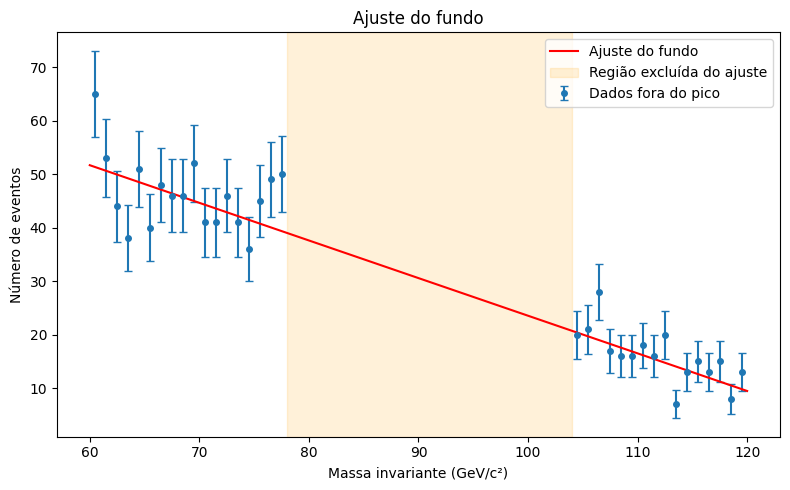

In [79]:
# Graus de liberdade: número de pontos menos número de parâmetros
graus_liberdade = len(x_fundo) - numpars
chi2_reduzido = chisqr / graus_liberdade

print(f"Qui-quadrado reduzido: {chi2_reduzido:.2f}")

# Calcula a curva em vários pontos para desenhá-la
x_curva = np.linspace(Min, Max, 500)
y_curva = np.polynomial.polynomial.polyval(x_curva, a_fit)

plt.figure(figsize=(8, 5))

plt.errorbar(
    x_fundo, y_fundo, yerr=erro_fundo,
    fmt="o", markersize=4, capsize=3,
    label="Dados fora do pico"
)

plt.plot(x_curva, y_curva, color="red", label="Ajuste do fundo")

plt.axvspan(
    peakmin, peakmax,
    color="orange", alpha=0.15,
    label="Região excluída do ajuste"
)

plt.xlabel("Massa invariante (GeV/c²)")
plt.ylabel("Número de eventos")
plt.title("Ajuste do fundo")
plt.legend()
plt.tight_layout()
plt.show()

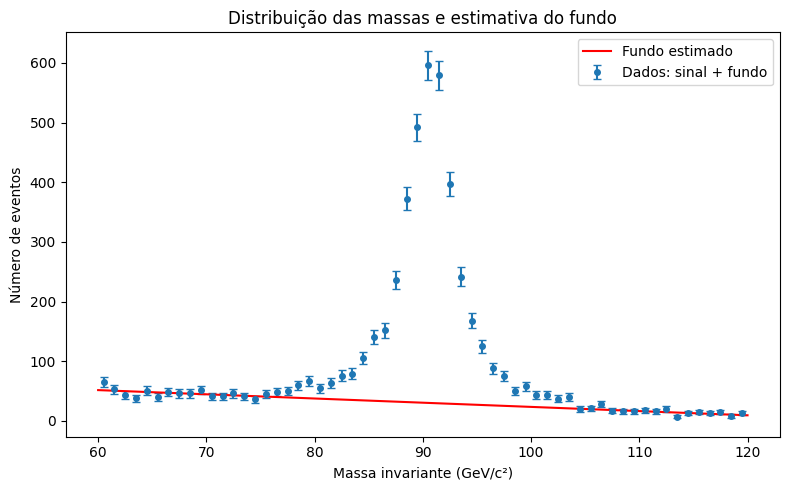

In [80]:
# Estima o fundo no centro de cada intervalo
fundo_estimado = np.polynomial.polynomial.polyval(centros_m, a_fit)

plt.figure(figsize=(8, 5))

# Todos os pontos, incluindo o pico
plt.errorbar(
    centros_m, contagens_m, yerr=erros_m,
    fmt="o", markersize=4, capsize=3,
    label="Dados: sinal + fundo"
)

# Curva ajustada na etapa anterior
plt.plot(
    x_curva, y_curva,
    color="red", label="Fundo estimado"
)

plt.xlabel("Massa invariante (GeV/c²)")
plt.ylabel("Número de eventos")
plt.title("Distribuição das massas e estimativa do fundo")
plt.legend()
plt.tight_layout()
plt.savefig("massas_com_fundo.png", dpi=300, bbox_inches="tight")
plt.show()

In [81]:
erro_fundo_estimado = []

for massa in centros_m:
    # Potências usadas no polinômio: [1, massa, massa², ...]
    v = np.array([massa**j for j in range(numpars)])

    variancia = v @ cov_fundo @ v
    erro_fundo_estimado.append(np.sqrt(variancia))

erro_fundo_estimado = np.array(erro_fundo_estimado)

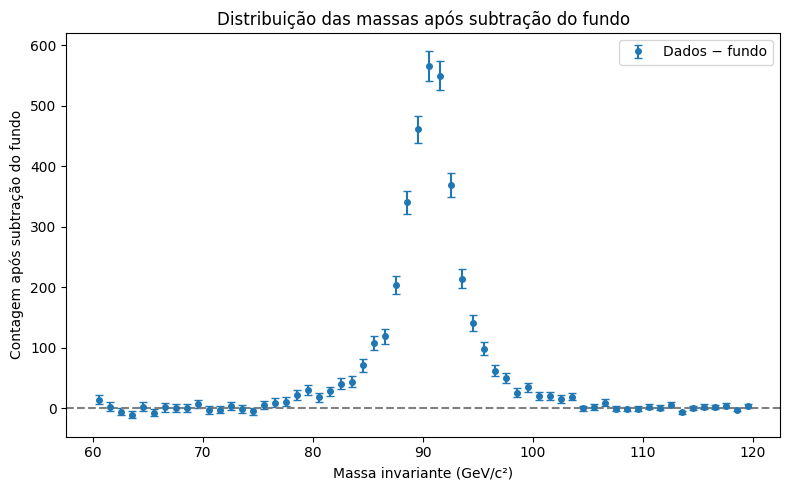

In [82]:
# Subtrai o fundo em cada intervalo
sinal = contagens_m - fundo_estimado

# Variância do sinal na região excluída do ajuste
variancia_sinal = erros_m**2 + erro_fundo_estimado**2

# Nos pontos usados no ajuste, dados e fundo estão correlacionados
variancia_sinal[fora_do_pico] = (
    erros_m[fora_do_pico]**2
    - erro_fundo_estimado[fora_do_pico]**2
)

# Evita valores negativos minúsculos causados por arredondamento
erro_sinal = np.sqrt(np.maximum(variancia_sinal, 0))

plt.figure(figsize=(8, 5))

plt.errorbar(
    centros_m, sinal, yerr=erro_sinal,
    fmt="o", markersize=4, capsize=3,
    label="Dados − fundo"
)

plt.axhline(0, color="gray", linestyle="--")

plt.xlabel("Massa invariante (GeV/c²)")
plt.ylabel("Contagem após subtração do fundo")
plt.title("Distribuição das massas após subtração do fundo")
plt.legend()
plt.tight_layout()
plt.savefig("sinal_sem_fundo.png", dpi=300, bbox_inches="tight")
plt.show()

# Dia 3:

In [83]:
from scipy.optimize import curve_fit

# Função que vamos ajustar ao pico
def Gaus(x, amplitude, mean, sigma):
    return amplitude * np.exp(-(x - mean)**2 / (2*sigma**2))

In [84]:
# Seleciona a região do pico
no_pico = (centros_m >= peakmin) & (centros_m <= peakmax)

x_pico = centros_m[no_pico]
y_pico = sinal[no_pico]
erro_pico = erro_sinal[no_pico]

In [85]:
# Estimativas iniciais para ajudar o ajuste
amplitude_inicial = np.max(y_pico)
media_inicial = x_pico[np.argmax(y_pico)]
sigma_inicial = 3.0  # GeV/c²

gausParams, gausCov = curve_fit(
    Gaus,
    x_pico,
    y_pico,
    p0=[amplitude_inicial, media_inicial, sigma_inicial],
    sigma=erro_pico,
    absolute_sigma=True,
    bounds=([0, peakmin, 0], [np.inf, peakmax, np.inf])
)

# Incertezas dos parâmetros
gausErros = np.sqrt(np.diag(gausCov))

amplitude, media, sigma_gauss = gausParams
erro_amplitude, erro_media, erro_sigma = gausErros

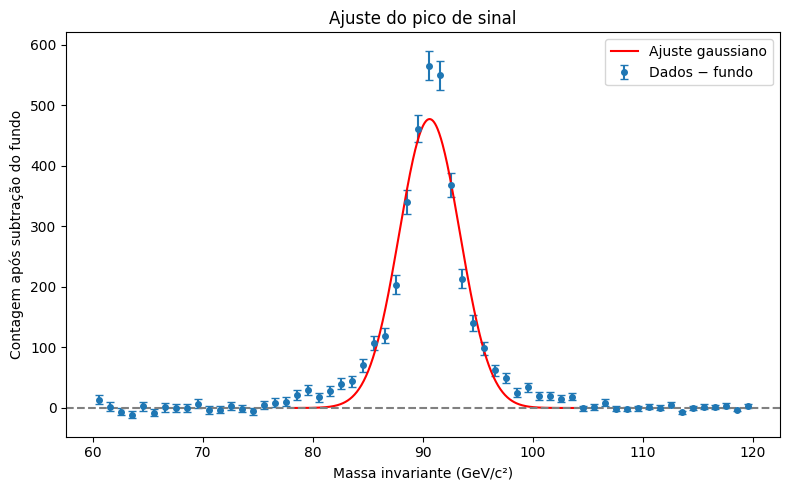

Centro do pico: (90.592 ± 0.054) GeV/c²
Largura sigma: (2.753 ± 0.049) GeV/c²


In [86]:
# Pontos próximos para desenhar uma curva suave
xGaus = np.linspace(peakmin, peakmax, 501)
yGaus = Gaus(xGaus, amplitude, media, sigma_gauss)

plt.figure(figsize=(8, 5))

plt.errorbar(
    centros_m, sinal, yerr=erro_sinal,
    fmt="o", markersize=4, capsize=3,
    label="Dados − fundo"
)

plt.plot(xGaus, yGaus, color="red", label="Ajuste gaussiano")
plt.axhline(0, color="gray", linestyle="--")

plt.xlabel("Massa invariante (GeV/c²)")
plt.ylabel("Contagem após subtração do fundo")
plt.title("Ajuste do pico de sinal")
plt.legend()
plt.tight_layout()
plt.savefig("ajuste_gaussiano.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Centro do pico: ({media:.3f} ± {erro_media:.3f}) GeV/c²")
print(f"Largura sigma: ({sigma_gauss:.3f} ± {erro_sigma:.3f}) GeV/c²")

In [87]:
# Valores previstos pelo ajuste nos pontos usados
previsao = Gaus(x_pico, amplitude, media, sigma_gauss)

chi2_gauss = np.sum(((y_pico - previsao) / erro_pico)**2)
gl_gauss = len(x_pico) - 3

print(f"Qui-quadrado reduzido: {chi2_gauss / gl_gauss:.2f}")

Qui-quadrado reduzido: 9.23


In [88]:
# Seleciona os intervalos da janela do pico
no_pico = (centros_m >= peakmin) & (centros_m <= peakmax)

# Contagens observadas e fundo estimado nessa janela
N_dados = np.sum(contagens_m[no_pico])
N_fundo = np.sum(fundo_estimado[no_pico])
N_sinal = N_dados - N_fundo

# Incerteza da soma das contagens observadas
variancia_dados = np.sum(erros_m[no_pico]**2)

# Propaga a incerteza do fundo somado na janela
v_soma = np.array([
    np.sum(centros_m[no_pico]**j)
    for j in range(numpars)
])

variancia_fundo = v_soma @ cov_fundo @ v_soma

erro_N_fundo = np.sqrt(variancia_fundo)
erro_N_sinal = np.sqrt(variancia_dados + variancia_fundo)

print(f"Janela: {peakmin:g}–{peakmax:g} GeV/c²")
print(f"Sinal: {N_sinal:.1f} ± {erro_N_sinal:.1f} eventos")
print(f"Fundo: {N_fundo:.1f} ± {erro_N_fundo:.1f} eventos")

Janela: 78–104 GeV/c²
Sinal: 3663.6 ± 70.8 eventos
Fundo: 776.4 ± 23.9 eventos


In [89]:
# Distância do sinal até zero, em unidades de sua incerteza
Z_aproximado = N_sinal / erro_N_sinal

print(f"Sinal: {N_sinal:.1f} ± {erro_N_sinal:.1f} eventos")
print(f"Distância de zero: {Z_aproximado:.2f} incertezas padrão")

Sinal: 3663.6 ± 70.8 eventos
Distância de zero: 51.75 incertezas padrão


O ajuste gaussiano apresentou qui-quadrado reduzido de 9,23, indicando que não descreve adequadamente todo o pico na janela escolhida. Os parâmetros obtidos caracterizam essa aproximação, e suas incertezas não incluem a inadequação do modelo. A contagem do sinal foi calculada separadamente pela subtração do fundo.

# [Referência do PDG:](https://pdg.lbl.gov/2026/listings/rpp2026-list-z-boson.pdf)

In [90]:
# Massa de referência: PDG 2026
massa_PDG = 91.1879
erro_massa_PDG = 0.0020

diferenca = abs(media - massa_PDG)
diferenca_percentual = 100 * diferenca / massa_PDG

incerteza_combinada = np.sqrt(erro_media**2 + erro_massa_PDG**2)
discrepancia = diferenca / incerteza_combinada

print(f"Massa pelo ajuste: ({media:.3f} ± {erro_media:.3f}) GeV/c²")
print(f"Massa do PDG: ({massa_PDG:.4f} ± {erro_massa_PDG:.4f}) GeV/c²")
print(f"Diferença percentual: {diferenca_percentual:.2f}%")
print(f"Discrepância nominal: {discrepancia:.2f} incertezas padrão")

Massa pelo ajuste: (90.592 ± 0.054) GeV/c²
Massa do PDG: (91.1879 ± 0.0020) GeV/c²
Diferença percentual: 0.65%
Discrepância nominal: 10.95 incertezas padrão


In [91]:
# Converte sigma em largura total à meia altura
fator = 2 * np.sqrt(2 * np.log(2))

fwhm = fator * sigma_gauss
erro_fwhm = fator * erro_sigma

print(f"FWHM da gaussiana: ({fwhm:.3f} ± {erro_fwhm:.3f}) GeV/c²")

FWHM da gaussiana: (6.482 ± 0.116) GeV/c²


In [92]:
# Largura natural do Z: PDG 2026, em GeV
Gamma_PDG = 2.4955
erro_Gamma_PDG = 0.0023

# Em c = 1, comparamos os valores numéricos das larguras
razao_larguras = fwhm / Gamma_PDG
diferenca_percentual_largura = (
    100 * abs(fwhm - Gamma_PDG) / Gamma_PDG
)

print(f"FWHM observada: {fwhm:.3f} ± {erro_fwhm:.3f} GeV/c²")
print(f"Largura natural do PDG: {Gamma_PDG:.4f} ± {erro_Gamma_PDG:.4f} GeV")
print(f"Razão entre as larguras: {razao_larguras:.2f}")
print(f"Diferença percentual: {diferenca_percentual_largura:.1f}%")

FWHM observada: 6.482 ± 0.116 GeV/c²
Largura natural do PDG: 2.4955 ± 0.0023 GeV
Razão entre as larguras: 2.60
Diferença percentual: 159.8%


## Conclusões:

O pico próximo de 91 GeV/c² no canal de dois múons aponta para o bóson Z. Para estimar o fundo, ajustei uma reta fora da região de 78 a 104 GeV/c², obtendo qui-quadrado reduzido de 0,95. Nessa janela, a subtração resultou em 3663,6 ± 70,8 eventos de sinal, com fundo estimado de 776,4 ± 23,9 eventos.

O ajuste gaussiano forneceu centro de 90,592 ± 0,054 GeV/c² e sigma de 2,753 ± 0,049 GeV/c². Entretanto, o qui-quadrado reduzido de 9,23 indica que a gaussiana não descreve bem todo o pico. As incertezas dos parâmetros não incluem essa inadequação nem todas as fontes de incerteza experimental. Nesse ajuste, também foram ignoradas as correlações entre os intervalos decorrentes da subtração do fundo.

A diferença percentual entre o centro ajustado e a massa do PDG foi de 0,65%, mas os valores não concordam dentro das incertezas consideradas. A FWHM gaussiana foi de 6,482 ± 0,116 GeV/c²; ela caracteriza o pico observado e não corresponde diretamente à largura natural Γ, pois a distribuição também sofre efeitos da resolução do detector e do modelo utilizado.

A razão entre a contagem de sinal e sua incerteza foi de 51,75. Esse indicador mostra um excesso claro dentro das hipóteses adotadas, mas não representa uma significância formal de descoberta. As incertezas das contagens dependem do modelo de fundo escolhido e não incluem a incerteza dessa escolha.